# Fungal Annotation with the q2-fungal-traits plugin

### Text what will be done

#### Setup and definition of variables:

In [15]:
import os
import pandas as pd
import numpy as np
from itertools import combinations
from scipy.stats import wilcoxon, mannwhitneyu, kruskal, fisher_exact
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, mannwhitneyu, kruskal, fisher_exact, spearmanr
%matplotlib inline

# ---------- base folders ----------
data_dir = "/home/jovyan/FunGut/data"
ign_dir  = f"{data_dir}/processed_ignored"
vis_dir  = f"{data_dir}/processed"

# ---------- existing inputs ----------
taxonomy_qza = f"{ign_dir}/03_taxonomy/taxonomy.qza"                # taxonomic classification of the ASVs
table_qza    = f"{ign_dir}/03_taxonomy/table_fungi_filtered.qza"    # ASV table, fungi only, NOT rarefied
rep_seqs_qza = f"{ign_dir}/03_taxonomy/rep_set_fungi_filtered.qza"  # ASV sequences
cm_dir       = f"{ign_dir}/06_diversity/core_metrics"               # core-metrics results (unfiltered)
rarefied_qza = f"{cm_dir}/rarefied_table.qza"                       # rarefied ASV table
metadata     = f"{ign_dir}/06_diversity/Final_metadata_with_GHSL.tsv"

# ---------- fungal-traits environment ----------
ft_env   = "/home/jovyan/envs/q2-fungal-traits"
ft_qiime = f"conda run --no-capture-output -p {ft_env} qiime"

# ---------- output folders ----------
base = "Fungal_Annotation"
annot_dir,  annot_vis  = f"{ign_dir}/{base}/01_annotation",           f"{vis_dir}/{base}/01_annotation"
cur_dir,    cur_vis    = f"{ign_dir}/{base}/02_curation",             f"{vis_dir}/{base}/02_curation"
filt_dir,   filt_vis   = f"{ign_dir}/{base}/03_nonintrinsic",         f"{vis_dir}/{base}/03_nonintrinsic"
grp_dir,    grp_vis    = f"{ign_dir}/{base}/04_group_comparisons",    f"{vis_dir}/{base}/04_group_comparisons"
func_dir,   func_vis   = f"{ign_dir}/{base}/05_functional_diversity", f"{vis_dir}/{base}/05_functional_diversity"
ancom_dir,  ancom_vis  = f"{ign_dir}/{base}/06_ancombc",              f"{vis_dir}/{base}/06_ancombc"

# ---------- metadata columns ----------
cat_main = ["diet_type_sample", "gluten_sample", "ibd_sample", "Settlement_Type"]   # main focus, categorical
num_main = ["bmi_sample"]                                                           # main focus, numeric
cat_extra = ["sex_sample", "country_sample"]                                        # optional
num_extra = ["age_years_sample"]                                                    # optional

# ---------- files created during the workflow but will be used frequently ----------
traits_tsv     = f"{annot_dir}/fungal_traits_tsv/metadata.tsv"   # original trait table
traits_curated = f"{cur_dir}/traits_curated.tsv"                  # corrected trait table
exclude_tsv = f"{cur_dir}/exclude_samples_lifestyle.tsv"   # samples excluded from the lifestyle analyses
filtered_qza = f"{filt_dir}/rarefied_table_without_nonintrinsic.qza"   # rarefied table without non-intrinsic fungi
nonintr_tsv = f"{filt_dir}/nonintrinsic_asvs.tsv"     # step 3: list of non-intrinsic ASVs

# ---------- definitions created during workflow but will be used frequently ----------
# definition of "non-intrinsic" fungi
macro_fruitbodies = [
    "agaricoid", "apothecium_(hymenium_on_surface)", "clathroid", "clavarioid",
    "corticioid", "cyphelloid", "gasteroid", "gasteroid-hypogeous",
    "hysterothecium_(opening_slit-like)", "mazaedium_(pushpin-like)",
    "phalloid", "polyporoid", "tremelloid",
]
symbiont_lifestyles = ["arbuscular_mycorrhizal", "ectomycorrhizal", "lichenized"]
#kmers for Alpha Diversity
kmer_size       = 8
kmer_before_dir = f"{filt_dir}/kmer{kmer_size}_unfiltered"
kmer_after_dir  = f"{filt_dir}/kmer{kmer_size}_filtered"

for d in [annot_dir, annot_vis, cur_dir, cur_vis, filt_dir, filt_vis, grp_dir, grp_vis,
          func_dir, func_vis, ancom_dir, ancom_vis, kmer_before_dir, kmer_after_dir]:
    os.makedirs(d, exist_ok=True)

kmer_metrics = {      # kmerizer core-metrics calculates these two
    "Richness": ("observed_features", "observed_features_vector.qza"),
    "Shannon":  ("shannon",           "shannon_vector.qza"),
}

# alpha metrics
alpha_metrics = {                     # ASV level (as in core-metrics)
    "Richness": ("observed_features", "observed_features_vector.qza"),
    "Shannon":  ("shannon",           "shannon_vector.qza"),
    "Evenness": ("pielou_e",          "evenness_vector.qza"),
}
kmer_metrics = {                      # k-mer level (as in kmerizer core-metrics)
    "Richness": ("observed_features", "observed_features_vector.qza"),
    "Shannon":  ("shannon",           "shannon_vector.qza"),
}

# ===== step 5: functional (lifestyle) diversity =====
annot_ids_tsv   = f"{func_dir}/annotated_asvs.tsv"                   # ASVs with a lifestyle
life_unf_qza    = f"{func_dir}/lifestyle_table_unfiltered.qza"       # reads per lifestyle, unfiltered
life_filt_qza   = f"{func_dir}/lifestyle_table_filtered.qza"         # reads per lifestyle, filtered
life_alpha_unf  = f"{func_dir}/alpha_unfiltered"
life_alpha_filt = f"{func_dir}/alpha_filtered"
for d in [life_alpha_unf, life_alpha_filt]:
    os.makedirs(d, exist_ok=True)

beta_dir = f"{func_dir}/beta"
beta_vis = f"{func_vis}/beta"
os.makedirs(beta_dir, exist_ok=True)
os.makedirs(beta_vis, exist_ok=True)

print("Setup done.")

Setup done.


#### Define helper functions:

In [2]:
import zipfile, tempfile
from biom import load_table

def load_table_qza(path):
    """Feature table (.qza) -> DataFrame: rows = ASVs, columns = samples"""
    with zipfile.ZipFile(path) as z:
        inner = [n for n in z.namelist() if n.endswith("data/feature-table.biom")][0]
        tmp = tempfile.mkdtemp()
        z.extract(inner, tmp)
        return load_table(os.path.join(tmp, inner)).to_dataframe(dense=True)

def load_traits(path):
    """Trait table (.tsv) -> DataFrame with feature-id as index, without QIIME info rows"""
    t = pd.read_csv(path, sep="\t", index_col=0)
    return t[~t.index.astype(str).str.startswith("#")]

def load_alpha(path):
    """Alpha diversity (.qza) -> Series: sample-id (text) -> value"""
    with zipfile.ZipFile(path) as z:
        inner = [n for n in z.namelist() if n.endswith("data/alpha-diversity.tsv")][0]
        s = pd.read_csv(z.open(inner), sep="\t", index_col=0, dtype=str).iloc[:, 0]
        return s.astype(float)

def load_metadata(path):
    """Sample metadata (.tsv) -> DataFrame with sample-id as index"""
    m = pd.read_csv(path, sep="\t", index_col=0, dtype=str)
    return m[~m.index.astype(str).str.startswith("#")]

def load_before_after(before_dir, after_dir, metrics):
    """One row per sample x metric: columns before, after, metric"""
    parts = []
    for label, (_, fname) in metrics.items():
        before = load_alpha(f"{before_dir}/{fname}")
        after  = load_alpha(f"{after_dir}/{fname}")
        d = pd.concat({"before": before, "after": after}, axis=1).dropna()
        d["metric"] = label
        parts.append(d)
    return pd.concat(parts)

def wilcoxon_before_after(alpha_df):
    """Paired Wilcoxon test before vs. after, per metric, including effect sizes"""
    rows = []
    for metric, dd in alpha_df.groupby("metric", sort=False):
        changed = dd[dd["before"] != dd["after"]]
        diff = changed["after"] - changed["before"]
        pct  = diff / changed["before"] * 100
        try:
            W, p = wilcoxon(dd["before"], dd["after"])
        except ValueError:                       # all differences are 0
            W, p = np.nan, np.nan
        rows.append({"metric": metric, "n_samples": len(dd), "samples_changed": len(changed),
                     "median_before (all)": dd["before"].median(), "median_after (all)": dd["after"].median(),
                     "median_change (changed)": diff.median(), "median_%_change (changed)": pct.median(),
                     "largest_%_change": pct.abs().max(), "W": W, "p": p})
    return pd.DataFrame(rows)

def plot_before_after(alpha_df, res_df, level, filename):
    """One grey line per sample, before -> after, one panel per metric"""
    metrics = list(alpha_df["metric"].unique())
    fig, axes = plt.subplots(1, len(metrics), figsize=(3.7 * len(metrics), 3.8))
    for ax, metric in zip(np.atleast_1d(axes), metrics):
        dd = alpha_df[alpha_df["metric"] == metric]
        for _, r in dd.iterrows():
            ax.plot([0, 1], [r["before"], r["after"]], color="grey", alpha=0.3, lw=0.8)
        ax.boxplot([dd["before"], dd["after"]], positions=[0, 1], widths=0.4)
        p_adj = res_df.loc[(res_df["level"] == level) & (res_df["metric"] == metric), "p_BH"].values[0]
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Unfiltered", "Filtered"])
        ax.set_title(f"{metric}  (p_BH = {p_adj:.2g})")
    fig.suptitle(level)
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

print("Helper functions loaded.")

Helper functions loaded.


#### Load rarefied ASV table and metadata

In [4]:
rare = load_table_qza(rarefied_qza)                     # rarefied ASV table
meta = load_metadata(metadata)                          # sample metadata

if os.path.exists(filtered_qza):                                                       
    filt = load_table_qza(filtered_qza)
if os.path.exists(f"{filt_dir}/shannon_vector.qza"):                                   
    alpha_asv = load_before_after(cm_dir, filt_dir, alpha_metrics)
if os.path.exists(f"{kmer_after_dir}/shannon_vector.qza"):                             
    alpha_kmer = load_before_after(kmer_before_dir, kmer_after_dir, kmer_metrics)
if os.path.exists(f"{life_alpha_filt}/shannon_vector.qza"):                            
    alpha_func = load_before_after(life_alpha_unf, life_alpha_filt, alpha_metrics)

#### Install fungal-traits environment:

In [5]:
# Create environment:
!conda env create --prefix "$ft_env" --file https://raw.githubusercontent.com/bokulich-lab/q2-fungal-traits/refs/heads/main/environment-files/q2-fungal-traits-rachis-tiny-2026.10.yml
# Install plugin:
!conda run --no-capture-output -p "$ft_env" pip install "q2-fungal-traits@git+https://github.com/bokulich-lab/q2-fungal-traits.git"
# Update QUIIME plugin list:
!$ft_qiime dev refresh-cache
# Check if everything works:
!$ft_qiime fungal-traits annotate --help

Error loading anaconda-anon-usage: module 'conda.cli.install' has no attribute 'check_prefix'
Retrieving notices: done
Channels:
 - https://packages.qiime2.org/qiime2/2026.10/tiny/released
 - conda-forge
 - bioconda
 - defaults
Platform: linux-64
Solving environment: done

## Package Plan ##

  environment location: /home/jovyan/envs/q2-fungal-traits

  added / updated specs:
    - pip
    - rachis-tiny


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    _openmp_mutex-4.5          |           20_gnu          28 KB  conda-forge
    _python_abi3_support-1.0   |       hd8ed1ab_3           8 KB  conda-forge
    _r-mutex-1.0.1             |      anacondar_1           3 KB  conda-forge
    annotated-doc-0.0.5        |     pyhcf101f3_0          16 KB  conda-forge
    array-api-compat-1.16.0    |     pyhc364b38_0          63 KB  conda-forge
    atpublic-9.0.0             |     pyhd8ed1ab_0        

## 01 Annotation

#### Annotate the taxonomy with fungal traits:

In [8]:
!$ft_qiime fungal-traits annotate \
  --i-taxonomy "$taxonomy_qza" \
  --o-fungal-traits "$annot_dir/fungal_traits.qza"

!$ft_qiime tools export \
  --input-path "$annot_dir/fungal_traits.qza" \
  --output-path "$annot_dir/fungal_traits_tsv"

Saved ImmutableMetadata to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/01_annotation/fungal_traits.qza
Exported /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/01_annotation/fungal_traits.qza as ImmutableMetadataDirectoryFormat to directory /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/01_annotation/fungal_traits_tsv


In [9]:
!qiime metadata tabulate \
  --m-input-file "$traits_tsv" \
  --o-visualization "$annot_vis/fungal_traits.qzv"

Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/01_annotation/fungal_traits.qzv


#### Get an overview over the annotation and check if it looks correct in the non-rarefied and rarefied ASV tables. We will further use the rarefied ASV table created during the Alpha Diversity workflow. The depth was set at 1600, based on a alpha rarefaction plot:

In [10]:
traits = load_traits(traits_tsv)
rare   = load_table_qza(rarefied_qza)    # rarefied ASV table (from core-metrics)
raw    = load_table_qza(table_qza)       # non-rarefied ASV table

print("ASVs in trait table:", len(traits))
print("  with lifestyle annotation:", traits["primary_lifestyle"].notna().sum())
print("  without annotation:       ", traits["primary_lifestyle"].isna().sum())
print()

for name, tab in [("Rarefied table", rare), ("Non-rarefied table", raw)]:
    found = tab.index.isin(traits.index)
    print(f"{name}: {tab.shape[0]} ASVs, {tab.shape[1]} samples | "
          f"{found.sum()} ASVs found in trait table "
          f"({tab[found].values.sum() / tab.values.sum() * 100:.1f}% of reads)")
print("Reads per sample (rarefied):", sorted(rare.sum().unique()))

for col in ["fruitbody_type_template", "primary_lifestyle", "growth_form_template"]:
    print(f"\n===== {col}")
    print(traits[col].value_counts(dropna=False))

ASVs in trait table: 681
  with lifestyle annotation: 491
  without annotation:        190

Rarefied table: 547 ASVs, 150 samples | 547 ASVs found in trait table (100.0% of reads)
Non-rarefied table: 575 ASVs, 150 samples | 575 ASVs found in trait table (100.0% of reads)
Reads per sample (rarefied): [np.float64(16000.0)]

===== fruitbody_type_template
fruitbody_type_template
none                                             317
NaN                                              293
perithecium_(hymenium_hidden,_narrow_opening)     35
agaricoid                                         11
cleistothecium_(closed,_spherical)                 7
polyporoid                                         5
corticioid                                         5
apothecium_(hymenium_on_surface)                   4
other                                              2
clavarioid                                         1
cyphelloid                                         1
Name: count, dtype: int64

===== primar

-> We see that the non-rarefied table (= table with reads per ASV per fungi, filtered to fungi) has 575 (from the total initially detected 681) ASVs, some have been removed during 03_taxonomy because they were non-fungi. The rarefied table created in 06_diversity has a bit less ASVs (547) because some very rare ones were lost during rarefying to an equal depth of 1600. In both table 100% of ASVs are found in the trait table, which is what we wanted to check.
#### There are 190 ASVs without "primary lifestyle" annotation, lets look at those:

In [12]:
import numpy as np

unann = traits[traits["primary_lifestyle"].isna()].copy()
unann["genus"] = unann["taxon"].str.extract(r"g__([^;]+)")[0]
unann["category"] = np.select(
    [unann["genus"].isna() | unann["genus"].str.contains("unidentified", na=False),
     unann["genus"].str.contains("Incertae_sedis", na=False)],
    ["no genus", "genus incertae sedis"],
    default="named genus")
unann["in_table"] = unann.index.isin(rare.index)
unann["reads"]    = rare.reindex(unann.index).sum(axis=1)       # reads in the rarefied table (0 if not present)

# 1. overview by category
print(unann.groupby("category").agg(ASVs=("taxon", "size"),
                                    ASVs_in_table=("in_table", "sum"),
                                    reads=("reads", "sum")))

# 2. share of unannotated reads per sample (%)
share_before = rare.loc[rare.index.isin(unann.index)].sum() / rare.sum() * 100
print("\nShare of unannotated reads per sample (%):")
print(share_before.describe().round(2))
print("Samples with >50%:", (share_before > 50).sum())

# 3. named genera = candidates for correction
print("\nNamed genera without annotation:")
print(unann[unann["category"] == "named genus"]
      .groupby("genus").agg(ASVs=("taxon", "size"), reads=("reads", "sum"))
      .sort_values("reads", ascending=False))

# 4. the 10 unannotated ASVs with the most reads, with full taxonomy
pd.set_option("display.max_colwidth", None)
unann.sort_values("reads", ascending=False).head(10)[["reads", "category", "taxon"]]

                      ASVs  ASVs_in_table    reads
category                                          
genus incertae sedis    11             11  13797.0
named genus             17             15  18311.0
no genus               162             52  41335.0

Share of unannotated reads per sample (%):
count    150.00
mean       3.06
std       12.06
min        0.00
25%        0.00
50%        0.00
75%        0.12
max       98.19
dtype: float64
Samples with >50%: 3

Named genera without annotation:
                    ASVs    reads
genus                            
Oligophagozyma         5  18198.0
Podila                 1     32.0
Linnemannia            2     20.0
Pseudopeyronellaea     1     16.0
Candolleomyces         1     12.0
Holleya                1     11.0
Proxiovicillium        2     10.0
Maudiozyma             1      9.0
Alloacremonium         1      2.0
Waltergamsia           1      1.0
Limtongozyma           1      0.0


,reads,category,taxon
feature-id,,,
6f2f7df5a1e2c18abe0b74bdb5a6a5f5,33821.0,no genus,k__Fungi;p__Ascomycota;c__Saccharomycetes;o__Saccharomycetales;f__Dipodascaceae
ade5af8c37bb12d50304dfba8581e10e,17077.0,named genus,k__Fungi;p__Ascomycota;c__Saccharomycetes;o__Saccharomycetales;f__Saccharomycetaceae;g__Oligophagozyma;s__Oligophagozyma_castellii
3cdc87eb8f6c0721b900fe62f8aa214a,13700.0,genus incertae sedis,k__Fungi;p__Ascomycota;c__Saccharomycetes;o__Saccharomycetales;f__Dipodascaceae;g__Dipodascaceae_gen_Incertae_sedis;s__Dipodascaceae_sp
7d75afa6401de7f9c1d9cfbef24ab309,4526.0,no genus,k__Fungi;p__Ascomycota;c__Saccharomycetes;o__Saccharomycetales;f__Dipodascaceae
6ffd3dbcfbee803f35e5fe4e5649b1e8,2177.0,no genus,k__Fungi;p__Ascomycota;c__Saccharomycetes;o__Saccharomycetales;f__Dipodascaceae
4073a8e805c574783cbf9ae9b5b930c1,1052.0,named genus,k__Fungi;p__Ascomycota;c__Saccharomycetes;o__Saccharomycetales;f__Saccharomycetaceae;g__Oligophagozyma;s__Oligophagozyma_castellii
d7300937139cd8e712fa65d74a1eaed4,198.0,no genus,k__Fungi;p__Ascomycota;c__Saccharomycetes;o__Saccharomycetales;f__Dipodascaceae
8197f79fb9bdad0f9c1feec25bc66e12,101.0,no genus,k__Fungi;p__Ascomycota;c__Dothideomycetes;o__Pleosporales;f__Didymellaceae
93cb21f5c699c523e48a0168cbfbbda7,64.0,no genus,k__Fungi;p__Ascomycota;c__Saccharomycetes;o__Saccharomycetales


-> We can see that 17 of the unannotated ASVs have a classification on genus level (as listed below), but the database that fungal-traits uses just doesnt know them. We can correct those if we find out, what primary lifestyle they have.

-> We see the share of unannotated reads per sample. Most samples have not many (75% quartile is only 0.12) but there are 3 samples with >50% unannotated reads and the maximum is 98.19% unannotated reads in one sample. Maybe this can be improved after annotating the genus level ASVs by hand. Below we can see the 10 unannotated ASVs with the most reads and the top 1 is one with no genus, which cant be corrected

#### Correct "named genus" ASVs by hand where we can/know and assign "yeast" to Dipodascaceae because no matter what genus, all in this family are yeasts:

In [13]:
# (A) Genera described or renamed after FungalTraits v1.2 (Dec 2020): take the former genus's traits.
#     Values looked up in FungalTraits v1.2 (the plugin's database).
genus_map = {
    # genus in data      former genus     primary                  secondary            growth form             fruitbody
    "Oligophagozyma": ("Candida",       "nectar/tap_saprotroph", "",                  "yeast",                "none"),
    "Maudiozyma":     ("Kazachstania",  "nectar/tap_saprotroph", "",                  "yeast",                "none"),
    "Podila":         ("Mortierella",   "soil_saprotroph",       "root-associated",   "filamentous_mycelium", "none"),
    "Linnemannia":    ("Mortierella",   "soil_saprotroph",       "root-associated",   "filamentous_mycelium", "none"),
    "Candolleomyces": ("Psathyrella",   "wood_saprotroph",       "litter_saprotroph", "filamentous_mycelium", "agaricoid"),
}

# (B) Dipodascaceae without a genus: all genera of the family are yeasts -> growth form "yeast".
#     Lifestyle differs within the family (5/6 nectar/tap_saprotroph, Magnusiomyces animal_parasite).
assign_dipodascaceae_lifestyle = False      # Switch: False = leave lifestyle empty, True = nectar/tap_saprotroph

cols = ["primary_lifestyle", "secondary_lifestyle", "growth_form_template", "fruitbody_type_template"]

t = pd.read_csv(traits_tsv, sep="\t", dtype=str, keep_default_na=False)   # ORIGINAL trait table
id_col = t.columns[0]
genus  = t["taxon"].str.extract(r"g__([^;]+)")[0]
family = t["taxon"].str.extract(r"f__([^;]+)")[0]
unannotated = t["primary_lifestyle"] == ""

# new column that documents every change
t["curation"] = ""
t.loc[t[id_col] == "#q2:types", "curation"] = "categorical"   # column type for QIIME

# (A)
for g, (old, *values) in genus_map.items():
    m = unannotated & (genus == g)
    t.loc[m, cols] = values
    t.loc[m, "curation"] = f"genus not in FungalTraits v1.2; traits of former genus {old}"

# (B)
m = unannotated & (family == "Dipodascaceae") & \
    (genus.isna() | genus.str.contains("Incertae_sedis|unidentified", na=False))
t.loc[m, "growth_form_template"] = "yeast"
note = "Dipodascaceae without genus; growth form yeast (all genera of the family)"
if assign_dipodascaceae_lifestyle:
    t.loc[m, "primary_lifestyle"] = "nectar/tap_saprotroph"
    note += "; lifestyle nectar/tap_saprotroph (5 of 6 genera)"
t.loc[m, "curation"] = note

t.to_csv(traits_curated, sep="\t", index=False)
print("Saved:", traits_curated)

# overview: what was changed, and how many reads it affects
changed = t[(t["curation"] != "") & ~t[id_col].str.startswith("#")].set_index(id_col)
changed["reads"] = rare.reindex(changed.index).sum(axis=1)
changed.groupby("curation").agg(ASVs=("reads", "size"), reads=("reads", "sum"))

Saved: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/02_curation/traits_curated.tsv


,ASVs,reads
curation,,
Dipodascaceae without genus; growth form yeast (all genera of the family),7,54465.0
genus not in FungalTraits v1.2; traits of former genus Candida,5,18198.0
genus not in FungalTraits v1.2; traits of former genus Kazachstania,1,9.0
genus not in FungalTraits v1.2; traits of former genus Mortierella,3,52.0
genus not in FungalTraits v1.2; traits of former genus Psathyrella,1,12.0


#### Now we check if only the intended rows were changed:

In [15]:
orig = pd.read_csv(traits_tsv, sep="\t", dtype=str, keep_default_na=False)
cur  = pd.read_csv(traits_curated, sep="\t", dtype=str, keep_default_na=False)
id_col = cur.columns[0]

diff = orig.ne(cur[orig.columns])           # compares every cell in the original columns
print("Rows:", len(orig), "->", len(cur))
print("New columns:", [c for c in cur.columns if c not in orig.columns])
print("Changed rows:", diff.any(axis=1).sum())
print("Changed columns:", list(diff.columns[diff.any()]))
print("Rows with a curation note:", (cur["curation"].ne("") & ~cur[id_col].str.startswith("#")).sum())

Rows: 682 -> 682
New columns: ['curation']
Changed rows: 17
Changed columns: ['primary_lifestyle', 'secondary_lifestyle', 'growth_form_template', 'fruitbody_type_template']
Rows with a curation note: 17


#### Save visualization:

In [16]:
!qiime metadata tabulate --m-input-file "$traits_curated" --o-visualization "$cur_vis/traits_curated.qzv"

Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/02_curation/traits_curated.qzv


#### Compare new trait table (curated) with old/original one:

In [17]:
tr_before = load_traits(traits_tsv)
tr_after  = load_traits(traits_curated)

def unannotated_share(tr, col):
    """% of reads per sample from ASVs without an entry in column col"""
    ids = tr.index[tr[col].isna()]
    return rare.loc[rare.index.isin(ids)].sum() / rare.sum() * 100

rows = {}
for col in ["primary_lifestyle", "growth_form_template"]:
    for label, tr in [("before", tr_before), ("after", tr_after)]:
        s = unannotated_share(tr, col)
        rows[(col, label)] = {
            "unannotated ASVs in table": int(rare.index.isin(tr.index[tr[col].isna()]).sum()),
            "mean %": round(s.mean(), 2),
            "75th percentile %": round(s.quantile(0.75), 2),
            "max %": round(s.max(), 2),
            "samples >50%": int((s > 50).sum()),
        }
pd.DataFrame(rows).T

unannotated ASVs in table  mean %  \
primary_lifestyle    before                       78.0    3.06   
                     after                        69.0    2.30   
growth_form_template before                       78.0    3.06   
                     after                        62.0    0.03   

                             75th percentile %  max %  samples >50%  
primary_lifestyle    before               0.12  98.19           3.0  
                     after                0.07  70.96           2.0  
growth_form_template before               0.12  98.19           3.0  
                     after                0.00   1.05           0.0

#### Lets look at the 2 samples we have to exclude from the analysis (because they have over 50% unannotated reads)

In [18]:
share_life = unannotated_share(tr_after, "primary_lifestyle")
exclude = share_life[share_life > 50].sort_values(ascending=False)
print(len(exclude), "samples with >50% reads without a lifestyle:\n")

unann_ids = tr_after.index[tr_after["primary_lifestyle"].isna()]
for s in exclude.index:
    top = rare.loc[rare.index.isin(unann_ids), s].sort_values(ascending=False).head(1)
    print(f"{s}: {exclude[s]:.1f}% unannotated | dominant ASV: {int(top.iloc[0])} reads, "
          f"{tr_after.loc[top.index[0], 'taxon'].split(';')[-1]}")

if len(exclude) > 0:
    pd.DataFrame(index=pd.Index(exclude.index, name="sample-id")).to_csv(exclude_tsv, sep="\t")
    print("\nSaved:", exclude_tsv)

2 samples with >50% reads without a lifestyle:

ERR5327488: 71.0% unannotated | dominant ASV: 11353 reads, s__Dipodascaceae_sp
ERR5327599: 60.9% unannotated | dominant ASV: 9750 reads, f__Dipodascaceae

Saved: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/02_curation/exclude_samples_lifestyle.tsv


In [19]:
meta = load_metadata(metadata)
excl = pd.read_csv(exclude_tsv, sep="\t", index_col=0).index.astype(str)

show_cols = cat_main + num_main + cat_extra + num_extra
out = meta.loc[meta.index.isin(excl), show_cols].copy()
out["% reads without lifestyle"] = share_life.reindex(out.index).round(1)
out

,diet_type_sample,gluten_sample,ibd_sample,Settlement_Type,bmi_sample,sex_sample,country_sample,age_years_sample,% reads without lifestyle
sample-id,,,,,,,,,
ERR5327488,NaN,NaN,NaN,NaN,NaN,NaN,Germany,NaN,71.0
ERR5327599,Omnivore,No,I do not have this condition,Rural,21.97,female,Isle of Man,58.0,60.9


-> Thats interesting: One of the samples has NaN in every column except country and the other one is the one sample from Isle of Man (and in the other categories lies in the majority -> omnivore, No gluten intolerance and no IBD). So we exclude those samples for this analysis.

# 02 Remove the non-intrinsic fungi

#### Define non-intrinsic fungi we want to remove and show reason why:

In [16]:
tr = load_traits(traits_curated)
is_macro = tr["fruitbody_type_template"].isin(macro_fruitbodies)
is_symb  = tr["primary_lifestyle"].isin(symbiont_lifestyles)

nonintr = tr.loc[is_macro | is_symb, ["fungal_traits_genus", "primary_lifestyle", "fruitbody_type_template"]].copy()
nonintr["reason"]  = np.select([is_macro[nonintr.index] & is_symb[nonintr.index], is_macro[nonintr.index]],
                               ["macrofungus + symbiont", "macrofungus"], default="symbiont")
nonintr["reads"]   = rare.reindex(nonintr.index).sum(axis=1)            # reads in the rarefied table
nonintr["samples"] = (rare.reindex(nonintr.index) > 0).sum(axis=1)      # in how many samples

nonintr_tsv = f"{filt_dir}/nonintrinsic_asvs.tsv"
nonintr.index.name = "feature-id"
nonintr.to_csv(nonintr_tsv, sep="\t")

print(f"{len(nonintr)} non-intrinsic ASVs, {(nonintr['reads'] > 0).sum()} of them in the rarefied table, "
      f"{int(nonintr['reads'].sum())} reads in total\n")
nonintr.sort_values("reads", ascending=False)

28 non-intrinsic ASVs, 27 of them in the rarefied table, 2085 reads in total



,fungal_traits_genus,primary_lifestyle,fruitbody_type_template,reason,reads,samples
feature-id,,,,,,
1d0faf5fd180a8fdb2bf814609069c4a,Agaricus,soil_saprotroph,agaricoid,macrofungus,1731.0,4
8f303470cc9b5cbad601ebcc1a2fb4a0,Thelephora,ectomycorrhizal,clavarioid,macrofungus + symbiont,80.0,1
a61a57ff7bf8cd2f0dde3fded4e6e280,Schizophyllum,wood_saprotroph,agaricoid,macrofungus,67.0,4
e36356de3a67a2e907d6c5f3fdfd4536,Coprinellus,soil_saprotroph,agaricoid,macrofungus,22.0,1
8072244bb3628c44525f3e417f52963d,Pleurotus,wood_saprotroph,agaricoid,macrofungus,21.0,6
4fa7b538790c3ae3629b0cbbd5a0da9f,Pleurotus,wood_saprotroph,agaricoid,macrofungus,19.0,9
2d2951754540277ad2e9bb93a62726ab,Trametes,wood_saprotroph,polyporoid,macrofungus,14.0,1
21968887d5b693085eccff9f6eef6b60,Porotheleum,wood_saprotroph,cyphelloid,macrofungus,13.0,1
4e6946addef87044bf3628a0365f3b9a,Microscypha,litter_saprotroph,apothecium_(hymenium_on_surface),macrofungus,12.0,1


#### Remove the defined fungi from the rarefied table

In [13]:
!qiime feature-table filter-features \
  --i-table "$rarefied_qza" \
  --m-metadata-file "$nonintr_tsv" \
  --p-exclude-ids \
  --o-filtered-table "$filtered_qza"

!qiime feature-table summarize \
  --i-table "$filtered_qza" \
  --o-feature-frequencies "$filt_dir/rarefied_table_without_nonintrinsic_feature_frequencies.qza" \
  --o-sample-frequencies "$filt_dir/rarefied_table_without_nonintrinsic_sample_frequencies.qza" \
  --o-summary "$filt_vis/rarefied_table_without_nonintrinsic.qzv"

Saved FeatureTable[Frequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/rarefied_table_without_nonintrinsic.qza
Saved ImmutableMetadata to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/rarefied_table_without_nonintrinsic_feature_frequencies.qza
Saved ImmutableMetadata to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/rarefied_table_without_nonintrinsic_sample_frequencies.qza
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/03_nonintrinsic/rarefied_table_without_nonintrinsic.qzv


#### Check that everything looks correct after removal:

In [14]:
filt = load_table_qza(filtered_qza)
removed_reads = rare.sum() - filt.reindex(columns=rare.columns).sum().fillna(0)

print("ASVs:   ", rare.shape[0], "->", filt.shape[0])
print("Samples:", rare.shape[1], "->", filt.shape[1])
print("Removed ASVs == ASVs on the list:",
      set(rare.index) - set(filt.index) == set(nonintr.index[nonintr["reads"] > 0]))
print("Samples affected:", (removed_reads > 0).sum())
print(f"Reads removed: {int(removed_reads.sum())} ({removed_reads.sum() / rare.values.sum() * 100:.3f}% of all reads)")
print("\nShare removed per affected sample (%):")
print((removed_reads[removed_reads > 0] / rare.sum()[removed_reads > 0] * 100).describe().round(2))

ASVs:    547 -> 520
Samples: 150 -> 150
Removed ASVs == ASVs on the list: True
Samples affected: 34
Reads removed: 2085 (0.087% of all reads)

Share removed per affected sample (%):
count    34.00
mean      0.38
std       1.84
min       0.01
25%       0.01
50%       0.03
75%       0.09
max      10.78
dtype: float64


-> So we can see that 27 ASVs were removed, which affected 34 samples and the share of reads removed in all affected samples was 0.38% (mean) and max 10.78%.

# 03 Alpha Diversity on filtered table (without non-intrinsic fungi)

#### ASV-level Alpha Diversity on filtered table:

In [28]:
for label, (metric, fname) in alpha_metrics.items():
    !qiime diversity alpha --i-table "{filtered_qza}" --p-metric {metric} --o-alpha-diversity "{filt_dir}/{fname}"

Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/observed_features_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/shannon_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/evenness_vector.qza


#### Kmer-level Alpha Diversity on unfiltered and filtered table (we do both again, so subsampling during rarefying is the same)

In [5]:
for table_in, out in [(rarefied_qza, kmer_before_dir), (filtered_qza, kmer_after_dir)]:
    !qiime kmerizer seqs-to-kmers --i-sequences "{rep_seqs_qza}" --i-table "{table_in}" --p-kmer-size {kmer_size} --o-kmer-table "{out}/kmer_table.qza"
    for label, (metric, fname) in kmer_metrics.items():
        !qiime diversity alpha --i-table "{out}/kmer_table.qza" --p-metric {metric} --o-alpha-diversity "{out}/{fname}"

Saved FeatureTable[Frequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/kmer8_unfiltered/kmer_table.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/kmer8_unfiltered/observed_features_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/kmer8_unfiltered/shannon_vector.qza
Saved FeatureTable[Frequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/kmer8_filtered/kmer_table.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/kmer8_filtered/observed_features_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/03_nonintrinsic/kmer8_filtered/shannon_vector.qza


#### Paired Wilcoxon test: alpha diversity unfiltered vs. filtered

In [6]:
def wilcoxon_before_after(alpha_df):
    rows = []
    for metric, dd in alpha_df.groupby("metric", sort=False):
        changed = dd[dd["before"] != dd["after"]]
        diff = changed["after"] - changed["before"]
        pct  = diff / changed["before"] * 100
        try:
            W, p = wilcoxon(dd["before"], dd["after"])
        except ValueError:                       # all differences are 0
            W, p = np.nan, np.nan
        rows.append({"metric": metric, "n_samples": len(dd), "samples_changed": len(changed),
                     "median_before (all)": dd["before"].median(), "median_after (all)": dd["after"].median(),
                     "median_change (changed)": diff.median(), "median_%_change (changed)": pct.median(),
                     "largest_%_change": pct.abs().max(), "W": W, "p": p})
    return pd.DataFrame(rows)

alpha_asv  = load_before_after(cm_dir, filt_dir, alpha_metrics)
alpha_kmer = load_before_after(kmer_before_dir, kmer_after_dir, kmer_metrics)

res4 = pd.concat([wilcoxon_before_after(alpha_asv).assign(level="ASV"),
                  wilcoxon_before_after(alpha_kmer).assign(level=f"k-mer (k={kmer_size})")],
                 ignore_index=True)
res4["p_BH"] = multipletests(res4["p"].fillna(1), method="fdr_bh")[1]     # across all 5 tests
res4.to_csv(f"{filt_dir}/alpha_before_after_wilcoxon.tsv", sep="\t", index=False)
res4.round(4)

,metric,n_samples,samples_changed,median_before (all),median_after (all),median_change (changed),median_%_change (changed),largest_%_change,W,p,level,p_BH
0,Richness,150,34,12.0000,12.0000,-1.0000,-7.6923,12.5000,0.0,0.0000,ASV,0.0000
1,Shannon,150,34,0.7138,0.7129,-0.0035,-0.4179,31.7493,0.0,0.0000,ASV,0.0000
2,Evenness,150,34,0.1965,0.2001,0.0027,1.9568,30.2569,74.0,0.0001,ASV,0.0001
3,Richness,150,34,1095.0000,1072.5000,-118.5000,-9.5798,19.6804,0.0,0.0000,k-mer (k=8),0.0000
4,Shannon,150,34,7.3126,7.3073,-0.0034,-0.0454,4.7947,0.0,0.0000,k-mer (k=8),0.0000


-> Removal of non-intrinsic fungi significantly reduced ASV richness (median −1 ASV, −7.7%) and Shannon diversity (−0.4%), slightly increased evenness (+2.0%), and reduced k-mer richness (k = 8; −9.6%) and k-mer Shannon diversity (−0.05%) in the 34 affected samples. Median values across all samples remained essentially unchanged.The p_BH values are very low, meaning the change is significant, all samples seem to change in the same direction. But the change is quite small (median change is very small), exception is the largest change, that probably comes from the sample that had 10% non-intrinsic fungi that were removed.

#### Figure for per-sample alpha diversity unfiltered vs. filtered

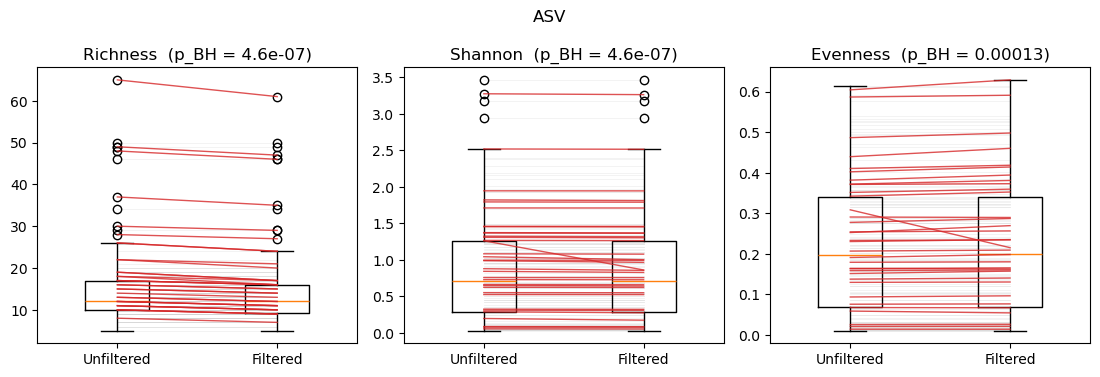

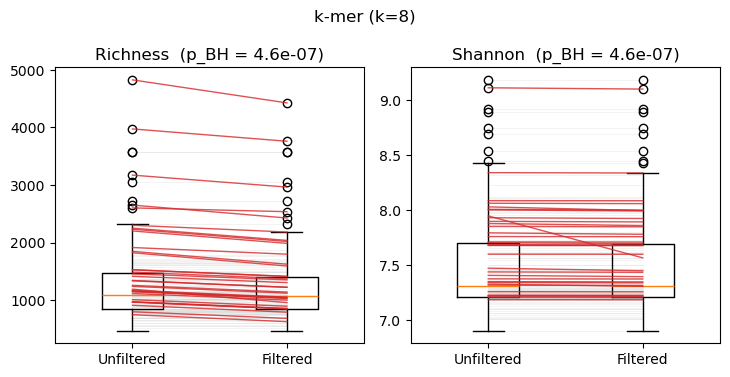

In [9]:
def plot_before_after(alpha_df, level, filename):
    metrics = list(alpha_df["metric"].unique())
    fig, axes = plt.subplots(1, len(metrics), figsize=(3.7 * len(metrics), 3.8))
    for ax, metric in zip(np.atleast_1d(axes), metrics):
        dd = alpha_df[alpha_df["metric"] == metric]
        for _, r in dd.iterrows():
            changed = r["before"] != r["after"]
            ax.plot([0, 1], [r["before"], r["after"]],
                color="tab:red" if changed else "lightgrey",
                alpha=0.8 if changed else 0.3, lw=1.0 if changed else 0.6,
                zorder=3 if changed else 1)
        ax.boxplot([dd["before"], dd["after"]], positions=[0, 1], widths=0.4)
        p_adj = res4.loc[(res4["level"] == level) & (res4["metric"] == metric), "p_BH"].values[0]
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Unfiltered", "Filtered"])
        ax.set_title(f"{metric}  (p_BH = {p_adj:.2g})")
    fig.suptitle(level)
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

plot_before_after(alpha_asv,  "ASV",                    f"{filt_vis}/alpha_before_after_ASV.png")
plot_before_after(alpha_kmer, f"k-mer (k={kmer_size})", f"{filt_vis}/alpha_before_after_kmer{kmer_size}.png")

# 05 Group comparisons

In [16]:
%%bash -s "$cm_dir" "$filt_dir" "$grp_vis" "$metadata"
cm_dir=$1; filt_dir=$2; vis_dir=$3; metadata=$4

for metric in shannon observed_features evenness; do
  # unfiltered (same input as earlier analysis)
  qiime diversity alpha-group-significance \
    --i-alpha-diversity $cm_dir/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/asv_unfiltered_${metric}_group_significance.qzv

  qiime diversity alpha-correlation \
    --i-alpha-diversity $cm_dir/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/asv_unfiltered_${metric}_correlation.qzv

  # filtered (without non-intrinsic fungi)
  qiime diversity alpha-group-significance \
    --i-alpha-diversity $filt_dir/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/asv_filtered_${metric}_group_significance.qzv

  qiime diversity alpha-correlation \
    --i-alpha-diversity $filt_dir/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/asv_filtered_${metric}_correlation.qzv
done

Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/asv_unfiltered_shannon_group_significance.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/asv_unfiltered_shannon_correlation.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/asv_filtered_shannon_group_significance.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/asv_filtered_shannon_correlation.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/asv_unfiltered_observed_features_group_significance.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/asv_unfiltered_observed_features_correlation.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/asv_filtered_observed_features_group_signif

In [17]:
%%bash -s "$kmer_before_dir" "$kmer_after_dir" "$grp_vis" "$metadata" "$kmer_size"
kmer_before=$1; kmer_after=$2; vis_dir=$3; metadata=$4; k=$5

for metric in shannon observed_features; do
  # unfiltered
  qiime diversity alpha-group-significance \
    --i-alpha-diversity $kmer_before/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/kmer${k}_unfiltered_${metric}_group_significance.qzv

  qiime diversity alpha-correlation \
    --i-alpha-diversity $kmer_before/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/kmer${k}_unfiltered_${metric}_correlation.qzv

  # filtered
  qiime diversity alpha-group-significance \
    --i-alpha-diversity $kmer_after/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/kmer${k}_filtered_${metric}_group_significance.qzv

  qiime diversity alpha-correlation \
    --i-alpha-diversity $kmer_after/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/kmer${k}_filtered_${metric}_correlation.qzv
done

Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/kmer8_unfiltered_shannon_group_significance.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/kmer8_unfiltered_shannon_correlation.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/kmer8_filtered_shannon_group_significance.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/kmer8_filtered_shannon_correlation.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/kmer8_unfiltered_observed_features_group_significance.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/kmer8_unfiltered_observed_features_correlation.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/04_group_comparisons/kmer8_filtered_observed_feature

#### Summary of group differences filtered vs. unfiltered (Groups with <= 3 samples are excluded here from statistical comparison):

In [18]:
rows = []
for level, df in [("ASV", alpha_asv), (f"k-mer (k={kmer_size})", alpha_kmer)]:
    for metric, dd in df.groupby("metric", sort=False):
        dd = dd.join(meta)
        for version in ["before", "after"]:
            # categorical columns: Kruskal-Wallis
            for col in cat_main + cat_extra:
                sub = dd.dropna(subset=[col])
                sizes = sub[col].value_counts()
                sub = sub[sub[col].isin(sizes[sizes >= 3].index)]          # only groups with >= 3 samples
                if sub[col].nunique() < 2:
                    continue
                try:
                    stat, p = kruskal(*[g[version] for _, g in sub.groupby(col)])
                except ValueError:
                    stat, p = np.nan, np.nan
                rows.append({"level": level, "metric": metric, "column": col, "test": "Kruskal-Wallis",
                             "version": version, "n": len(sub), "stat": stat, "p": p})
            # numeric columns: Spearman
            for col in num_main + num_extra:
                x = pd.to_numeric(dd[col], errors="coerce")
                ok = x.notna()
                stat, p = spearmanr(x[ok], dd.loc[ok, version])
                rows.append({"level": level, "metric": metric, "column": col, "test": "Spearman (rho)",
                             "version": version, "n": int(ok.sum()), "stat": stat, "p": p})

res5 = pd.DataFrame(rows)
res5["version"] = res5["version"].map({"before": "unfiltered", "after": "filtered"})
res5["p_BH"] = res5.groupby(["level", "metric", "version"])["p"].transform(
    lambda p: multipletests(p.fillna(1), method="fdr_bh")[1])
res5.to_csv(f"{grp_dir}/alpha_group_tests_unfiltered_vs_filtered.tsv", sep="\t", index=False)

table5 = res5.pivot_table(index=["level", "metric", "column", "test"], columns="version", values="p_BH")
table5 = table5[["unfiltered", "filtered"]]
table5["same_conclusion"] = (table5["unfiltered"] < 0.05) == (table5["filtered"] < 0.05)
pd.set_option("display.max_rows", None)
table5.round(4)

version                                               unfiltered  filtered  \
level       metric   column           test                                   
ASV         Evenness Settlement_Type  Kruskal-Wallis      0.7452    0.7557   
                     age_years_sample Spearman (rho)      0.8238    0.7742   
                     bmi_sample       Spearman (rho)      0.9156    0.9834   
                     country_sample   Kruskal-Wallis      0.7452    0.7557   
                     diet_type_sample Kruskal-Wallis      0.6114    0.6166   
                     gluten_sample    Kruskal-Wallis      0.6114    0.6166   
                     ibd_sample       Kruskal-Wallis      0.7452    0.7533   
                     sex_sample       Kruskal-Wallis      0.6114    0.6166   
            Richness Settlement_Type  Kruskal-Wallis      0.9899    0.9793   
                     age_years_sample Spearman (rho)      0.0578    0.0446   
                     bmi_sample       Spearman (rho)      0.7084    0.7335   
                     country_sample   Kruskal-Wallis      0.5412    0.4799   
                     diet_type_sample Kruskal-Wallis      0.0141    0.0109   
                     gluten_sample    Kruskal-Wallis      0.7084    0.7490   
                     ibd_sample       Kruskal-Wallis      0.1149    0.1078   
                     sex_sample       Kruskal-Wallis      0.0882    0.0691   
            Shannon  Settlement_Type  Kruskal-Wallis      0.7398    0.7607   
                     age_years_sample Spearman (rho)      0.9834    0.9523   
                     bmi_sample       Spearman (rho)      0.9834    0.9523   
                     country_sample   Kruskal-Wallis      0.5890    0.5730   
                     diet_type_sample Kruskal-Wallis      0.3088    0.3050   
                     gluten_sample    Kruskal-Wallis      0.5169    0.5300   
                     ibd_sample       Kruskal-Wallis      0.5169    0.5300   
                     sex_sample       Kruskal-Wallis      0.5169    0.5300   
k-mer (k=8) Richness Settlement_Type  Kruskal-Wallis      0.9672    0.9229   
                     age_years_sample Spearman (rho)      0.0266    0.0199   
                     bmi_sample       Spearman (rho)      0.9672    0.9229   
                     country_sample   Kruskal-Wallis      0.5441    0.3194   
                     diet_type_sample Kruskal-Wallis      0.0213    0.0151   
                     gluten_sample    Kruskal-Wallis      0.9672    0.9229   
                     ibd_sample       Kruskal-Wallis      0.1070    0.1217   
                     sex_sample       Kruskal-Wallis      0.2055    0.1633   
            Shannon  Settlement_Type  Kruskal-Wallis      0.4658    0.4385   
                     age_years_sample Spearman (rho)      0.2494    0.2648   
                     bmi_sample       Spearman (rho)      0.3381    0.3630   
                     country_sample   Kruskal-Wallis      0.3381    0.3609   
                     diet_type_sample Kruskal-Wallis      0.0072    0.0061   
                     gluten_sample    Kruskal-Wallis      0.3381    0.3609   
                     ibd_sample       Kruskal-Wallis      0.0972    0.1073   
                     sex_sample       Kruskal-Wallis      0.5655    0.5998   

version                                               same_conclusion  
level       metric   column           test                             
ASV         Evenness Settlement_Type  Kruskal-Wallis             True  
                     age_years_sample Spearman (rho)             True  
                     bmi_sample       Spearman (rho)             True  
                     country_sample   Kruskal-Wallis             True  
                     diet_type_sample Kruskal-Wallis             True  
                     gluten_sample    Kruskal-Wallis             True  
                     ibd_sample       Kruskal-Wallis             True  
                     sex_sample       Kruskal-Wallis             True  
   

-> False for Richness and age: Means that the age–richness correlation is significant in one version and not in the other. But here only slight shift from 0.0578 to 0.0446. But we didnt do Spearman before, so interesting to see that Richness changes significantly with age (even though Shannon does not and is the more robust value)

#### Look at the Richness for age values:

In [20]:
res5[(res5["metric"] == "Richness") & (res5["column"] == "age_years_sample")][
    ["level", "version", "n", "stat", "p", "p_BH"]].round(4)

,level,version,n,stat,p,p_BH
7,ASV,unfiltered,145,-0.2028,0.0145,0.0578
15,ASV,filtered,145,-0.2102,0.0111,0.0446
55,k-mer (k=8),unfiltered,145,-0.2244,0.0067,0.0266
63,k-mer (k=8),filtered,145,-0.2320,0.0050,0.0199


-> weak decrease of richness with age

#### Look at differences between filtered and unfiltered in pairwise comparisons (Groups with <= 3 samples are excluded here from statistical comparison):

In [19]:
pair_rows = []
for level, df in [("ASV", alpha_asv), (f"k-mer (k={kmer_size})", alpha_kmer)]:
    for metric, dd in df.groupby("metric", sort=False):
        dd = dd.join(meta)
        for col in cat_main + cat_extra:
            sub = dd.dropna(subset=[col])
            sizes = sub[col].value_counts()
            sub = sub[sub[col].isin(sizes[sizes >= 3].index)]           # only groups with >= 3 samples
            for g1, g2 in combinations(sorted(sub[col].unique()), 2):   # every pair of groups
                a, b = sub[sub[col] == g1], sub[sub[col] == g2]
                row = {"level": level, "metric": metric, "column": col,
                       "group_1": g1, "group_2": g2, "n_1": len(a), "n_2": len(b)}
                for version, label in [("before", "unfilt"), ("after", "filt")]:
                    try:
                        _, p = kruskal(a[version], b[version])
                    except ValueError:                                  # all values identical
                        p = np.nan
                    row[f"median_1_{label}"] = a[version].median()
                    row[f"median_2_{label}"] = b[version].median()
                    row[f"p_{label}"] = p
                pair_rows.append(row)

pairs5 = pd.DataFrame(pair_rows)
for label in ["unfilt", "filt"]:                                        # BH within each column (as in QIIME)
    pairs5[f"q_{label}"] = pairs5.groupby(["level", "metric", "column"])[f"p_{label}"].transform(
        lambda p: multipletests(p.fillna(1), method="fdr_bh")[1])
pairs5["same_conclusion"] = (pairs5["q_unfilt"] < 0.05) == (pairs5["q_filt"] < 0.05)
pairs5.to_csv(f"{grp_dir}/alpha_pairwise_unfiltered_vs_filtered.tsv", sep="\t", index=False)

print(len(pairs5), "pairwise comparisons in total,",
      (~pairs5["same_conclusion"]).sum(), "with a different conclusion after filtering\n")

cols_show = ["level", "metric", "column", "group_1", "group_2", "n_1", "n_2",
             "median_1_unfilt", "median_2_unfilt", "q_unfilt", "q_filt", "same_conclusion"]
pairs5.loc[(pairs5["q_unfilt"] < 0.05) | (pairs5["q_filt"] < 0.05), cols_show].round(4)

120 pairwise comparisons in total, 0 with a different conclusion after filtering



,level,metric,column,group_1,group_2,n_1,n_2,median_1_unfilt,median_2_unfilt,q_unfilt,q_filt,same_conclusion
0,ASV,Richness,diet_type_sample,Omnivore,Omnivore but do not eat red meat,118,8,13.0000,9.0000,0.0268,0.0190,True
1,ASV,Richness,diet_type_sample,Omnivore,Vegan,118,5,13.0000,22.0000,0.0142,0.0138,True
4,ASV,Richness,diet_type_sample,Omnivore but do not eat red meat,Vegan,8,5,9.0000,22.0000,0.0142,0.0138,True
7,ASV,Richness,diet_type_sample,Vegan,Vegetarian,5,6,22.0000,10.5000,0.0154,0.0151,True
8,ASV,Richness,diet_type_sample,Vegan,Vegetarian but eat seafood,5,8,22.0000,12.5000,0.0142,0.0138,True
17,ASV,Richness,sex_sample,female,male,69,79,11.0000,14.0000,0.0331,0.0259,True
28,ASV,Shannon,diet_type_sample,Omnivore but do not eat red meat,Vegan,8,5,0.3300,1.3083,0.0421,0.0421,True
30,ASV,Shannon,diet_type_sample,Omnivore but do not eat red meat,Vegetarian but eat seafood,8,8,0.3300,1.0340,0.0421,0.0421,True
72,k-mer (k=8),Richness,diet_type_sample,Omnivore,Omnivore but do not eat red meat,118,8,1098.5000,779.5000,0.0168,0.0154,True
73,k-mer (k=8),Richness,diet_type_sample,Omnivore,Vegan,118,5,1098.5000,1765.0000,0.0168,0.0154,True


-> Both (unfiltered and filtered) came to the same conclusion for pairwise comparison

# 05 Funcional Alpha Diversity

#### We calculate Alpha Diversity over "primary lifestyle" categories instead of ASVs. We here leave out the 2 samples with >50% unannotated reads we identified above!

#### This is the number of ASVs with a lifestyle:

In [24]:
tr = load_traits(traits_curated)
annotated = tr.index[tr["primary_lifestyle"].notna()]
pd.DataFrame(index=pd.Index(annotated, name="feature-id")).to_csv(annot_ids_tsv, sep="\t")
print(len(annotated), "ASVs with a lifestyle annotation")

501 ASVs with a lifestyle annotation


#### Remove the 2 samples, keep only ASVs with a lifestyle and add up the reads per lifestyle:

In [25]:
%%bash -s "$rarefied_qza" "$filtered_qza" "$exclude_tsv" "$annot_ids_tsv" "$traits_curated" "$func_dir"
rare=$1; filt=$2; exclude=$3; annotated=$4; traits=$5; out=$6

for version in unfiltered filtered; do
  if [ "$version" = "unfiltered" ]; then table=$rare; else table=$filt; fi

  # 1. remove the 2 excluded samples
  qiime feature-table filter-samples \
    --i-table $table \
    --m-metadata-file $exclude \
    --p-exclude-ids \
    --o-filtered-table $out/rarefied_${version}_noexcl.qza

  # 2. keep only ASVs with a lifestyle
  qiime feature-table filter-features \
    --i-table $out/rarefied_${version}_noexcl.qza \
    --m-metadata-file $annotated \
    --o-filtered-table $out/rarefied_${version}_annotated.qza

  # 3. add up reads per lifestyle
  qiime feature-table group \
    --i-table $out/rarefied_${version}_annotated.qza \
    --p-axis feature \
    --m-metadata-file $traits \
    --m-metadata-column primary_lifestyle \
    --p-mode sum \
    --o-grouped-table $out/lifestyle_table_${version}.qza
done

Saved FeatureTable[Frequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/rarefied_unfiltered_noexcl.qza
Saved FeatureTable[Frequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/rarefied_unfiltered_annotated.qza
Saved FeatureTable[Frequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/lifestyle_table_unfiltered.qza
Saved FeatureTable[Frequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/rarefied_filtered_noexcl.qza
Saved FeatureTable[Frequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/rarefied_filtered_annotated.qza
Saved FeatureTable[Frequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/lifestyle_table_filtered.qza


#### Check that we have 148 samples and which lifestyles differ between filtered and unfiltered:

In [9]:
for version, path in [("unfiltered", life_unf_qza), ("filtered", life_filt_qza)]:
    lt = load_table_qza(path)
    kept = lt.sum() / 16000 * 100
    print(f"===== {version}: {lt.shape[0]} lifestyles x {lt.shape[1]} samples")
    print(f"Reads kept per sample: median {kept.median():.1f}%, minimum {kept.min():.1f}%")
    print(lt.sum(axis=1).sort_values(ascending=False).astype(int), "\n")

===== unfiltered: 14 lifestyles x 148 samples
Reads kept per sample: median 100.0%, minimum 58.0%
nectar/tap_saprotroph     1696975
unspecified_saprotroph     385640
animal_parasite            130854
soil_saprotroph             62781
litter_saprotroph           55947
plant_pathogen                569
wood_saprotroph               419
dung_saprotroph               357
epiphyte                      149
sooty_mold                    123
ectomycorrhizal                82
foliar_endophyte               19
mycoparasite                   11
arthropod-associated            5
dtype: int64 

===== filtered: 12 lifestyles x 148 samples
Reads kept per sample: median 100.0%, minimum 58.0%
nectar/tap_saprotroph     1696975
unspecified_saprotroph     385640
animal_parasite            130854
soil_saprotroph             61005
litter_saprotroph           55925
plant_pathogen                565
dung_saprotroph               340
wood_saprotroph               240
epiphyte                      149
sooty_mol

#### Alpha Diversity over lifestyles (filtered and unfiltered):

In [27]:
for version, out in [("unfiltered", life_alpha_unf), ("filtered", life_alpha_filt)]:
    for label, (metric, fname) in alpha_metrics.items():
        !qiime diversity alpha --i-table "{func_dir}/lifestyle_table_{version}.qza" --p-metric {metric} --o-alpha-diversity "{out}/{fname}"

Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/alpha_unfiltered/observed_features_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/alpha_unfiltered/shannon_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/alpha_unfiltered/evenness_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/alpha_filtered/observed_features_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/alpha_filtered/shannon_vector.qza
Saved SampleData[AlphaDiversity] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/alpha_filtered/evenness_vector.qza


#### Compare results for filtered vs. unfiltered with paired Wilcoxon test:

,metric,n_samples,samples_changed,median_before (all),median_after (all),median_change (changed),median_%_change (changed),largest_%_change,W,p,level,p_BH
0,Richness,148,29,4.0000,3.5000,-1.0000,-25.0000,50.0000,0.0,0.0000,Lifestyle,0.0000
1,Shannon,148,34,0.0514,0.0514,-0.0034,-3.9817,58.2112,0.0,0.0000,Lifestyle,0.0000
2,Evenness,148,34,0.0266,0.0272,0.0039,9.6755,58.2112,122.0,0.0027,Lifestyle,0.0027


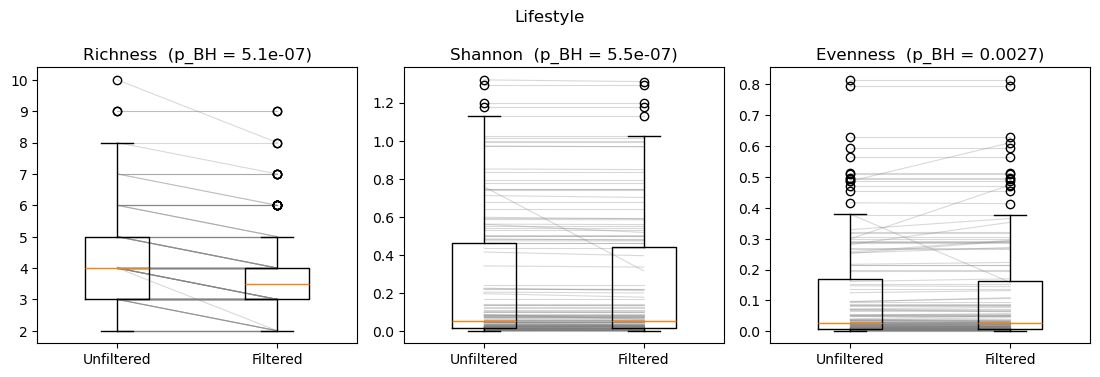

In [10]:
alpha_func = load_before_after(life_alpha_unf, life_alpha_filt, alpha_metrics)
res6 = wilcoxon_before_after(alpha_func).assign(level="Lifestyle")
res6["p_BH"] = multipletests(res6["p"].fillna(1), method="fdr_bh")[1]
res6.to_csv(f"{func_dir}/lifestyle_alpha_before_after_wilcoxon.tsv", sep="\t", index=False)
display(res6.round(4))

plot_before_after(alpha_func, res6, "Lifestyle", f"{func_vis}/lifestyle_alpha_before_after.png")

-> What this tells us: At the level of ecological lifestyles, samples were strongly dominated by a single lifestyle (median Shannon = 0.05, median evenness = 0.03, so both very low), with a median of 4 lifestyles per sample (richness). Removing non-intrinsic fungi eliminated at median one lifestyle in 29 of 148 samples (median −1 lifestyle), indicating that a part of lifestyle richness was contributed by (probably) diet-derived taxa.

#### Now the group comparisons on lifestyle level:

In [29]:
%%bash -s "$life_alpha_unf" "$life_alpha_filt" "$func_vis" "$metadata"
unf=$1; filt=$2; vis_dir=$3; metadata=$4

for metric in shannon observed_features evenness; do
  # unfiltered
  qiime diversity alpha-group-significance \
    --i-alpha-diversity $unf/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/lifestyle_unfiltered_${metric}_group_significance.qzv

  qiime diversity alpha-correlation \
    --i-alpha-diversity $unf/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/lifestyle_unfiltered_${metric}_correlation.qzv

  # filtered (without non-intrinsic fungi)
  qiime diversity alpha-group-significance \
    --i-alpha-diversity $filt/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/lifestyle_filtered_${metric}_group_significance.qzv

  qiime diversity alpha-correlation \
    --i-alpha-diversity $filt/${metric}_vector.qza \
    --m-metadata-file $metadata \
    --o-visualization $vis_dir/lifestyle_filtered_${metric}_correlation.qzv
done

Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/lifestyle_unfiltered_shannon_group_significance.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/lifestyle_unfiltered_shannon_correlation.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/lifestyle_filtered_shannon_group_significance.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/lifestyle_filtered_shannon_correlation.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/lifestyle_unfiltered_observed_features_group_significance.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/lifestyle_unfiltered_observed_features_correlation.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functio

-> The filtered Shannon group comparison showed no significant difference between any group.

#### Summary of overall group differences filtered and unfiltered (Groups with <= 3 samples are excluded here from statistical comparison):

In [13]:
rows = []
for metric, dd in alpha_func.groupby("metric", sort=False):
    dd = dd.join(meta)
    for version in ["before", "after"]:
        # categorical columns: Kruskal-Wallis
        for col in cat_main + cat_extra:
            sub = dd.dropna(subset=[col])
            sizes = sub[col].value_counts()
            sub = sub[sub[col].isin(sizes[sizes >= 3].index)]          # only groups with >= 3 samples
            if sub[col].nunique() < 2:
                continue
            try:
                stat, p = kruskal(*[g[version] for _, g in sub.groupby(col)])
            except ValueError:
                stat, p = np.nan, np.nan
            rows.append({"metric": metric, "column": col, "test": "Kruskal-Wallis",
                         "version": version, "n": len(sub), "stat": stat, "p": p})
        # numeric columns: Spearman
        for col in num_main + num_extra:
            x = pd.to_numeric(dd[col], errors="coerce")
            ok = x.notna()
            stat, p = spearmanr(x[ok], dd.loc[ok, version])
            rows.append({"metric": metric, "column": col, "test": "Spearman (rho)",
                         "version": version, "n": int(ok.sum()), "stat": stat, "p": p})

res6g = pd.DataFrame(rows)
res6g["level"] = "Lifestyle"
res6g["version"] = res6g["version"].map({"before": "unfiltered", "after": "filtered"})
res6g["p_BH"] = res6g.groupby(["metric", "version"])["p"].transform(
    lambda p: multipletests(p.fillna(1), method="fdr_bh")[1])
res6g.to_csv(f"{func_dir}/lifestyle_alpha_group_tests.tsv", sep="\t", index=False)

table6 = res6g.pivot_table(index=["metric", "column", "test"], columns="version", values="p_BH")
table6 = table6[["unfiltered", "filtered"]]
table6["same_conclusion"] = (table6["unfiltered"] < 0.05) == (table6["filtered"] < 0.05)
pd.set_option("display.max_rows", None)
table6.round(4)

version                                   unfiltered  filtered  \
metric   column           test                                   
Evenness Settlement_Type  Kruskal-Wallis      0.2565    0.2725   
         age_years_sample Spearman (rho)      0.0029    0.0033   
         bmi_sample       Spearman (rho)      0.4858    0.5455   
         country_sample   Kruskal-Wallis      0.1679    0.2256   
         diet_type_sample Kruskal-Wallis      0.1679    0.2256   
         gluten_sample    Kruskal-Wallis      0.2565    0.2256   
         ibd_sample       Kruskal-Wallis      0.1447    0.1503   
         sex_sample       Kruskal-Wallis      0.1679    0.2256   
Richness Settlement_Type  Kruskal-Wallis      0.8586    0.8830   
         age_years_sample Spearman (rho)      0.0501    0.0176   
         bmi_sample       Spearman (rho)      0.8586    0.8830   
         country_sample   Kruskal-Wallis      0.4952    0.1952   
         diet_type_sample Kruskal-Wallis      0.0707    0.0432   
         gluten_sample    Kruskal-Wallis      0.9499    0.8830   
         ibd_sample       Kruskal-Wallis      0.3574    0.1952   
         sex_sample       Kruskal-Wallis      0.8586    0.8638   
Shannon  Settlement_Type  Kruskal-Wallis      0.2960    0.3167   
         age_years_sample Spearman (rho)      0.0013    0.0012   
         bmi_sample       Spearman (rho)      0.4960    0.5067   
         country_sample   Kruskal-Wallis      0.1690    0.1367   
         diet_type_sample Kruskal-Wallis      0.1391    0.1367   
         gluten_sample    Kruskal-Wallis      0.2960    0.3167   
         ibd_sample       Kruskal-Wallis      0.1315    0.1367   
         sex_sample       Kruskal-Wallis      0.1690    0.1872   

version                                   same_conclusion  
metric   column           test                             
Evenness Settlement_Type  Kruskal-Wallis             True  
         age_years_sample Spearman (rho)             True  
         bmi_sample       Spearman (rho)             True  
         country_sample   Kruskal-Wallis             True  
         diet_type_sample Kruskal-Wallis             True  
         gluten_sample    Kruskal-Wallis             True  
         ibd_sample       Kruskal-Wallis             True  
         sex_sample       Kruskal-Wallis             True  
Richness Settlement_Type  Kruskal-Wallis             True  
         age_years_sample Spearman (rho)            False  
         bmi_sample       Spearman (rho)             True  
         country_sample   Kruskal-Wallis             True  
         diet_type_sample Kruskal-Wallis            False  
         gluten_sample    Kruskal-Wallis             True  
         ibd_sample       Kruskal-Wallis             True  
         sex_sample       Kruskal-Wallis             True  
Shannon  Settlement_Type  Kruskal-Wallis             True  
         age_years_sample Spearman (rho)             True  
         bmi_sample       Spearman (rho)             True  
         country_sample   Kruskal-Wallis             True  
         diet_type_sample Kruskal-Wallis             True  
         gluten_sample    Kruskal-Wallis             True  
         ibd_sample       Kruskal-Wallis             True  
         sex_sample       Kruskal-Wallis             True

-> Most interesting findings: Spearman analysis showed that Shannon diversity differs significantly with age. Richness differs significantly with age and diet for the filtered lifestyles but not for the unfiltered ones. The difference is not that big, it just happens to be enough to reach the threshhold of 0.05. Still it suggests, that food derived fungi do influence Alpha Diversity analysis. 

#### Summary of specific groups that differ before and after filtering (Groups with <= 3 samples are excluded here from statistical comparison):

In [11]:
pair_rows = []
for metric, dd in alpha_func.groupby("metric", sort=False):
    dd = dd.join(meta)
    for col in cat_main + cat_extra:
        sub = dd.dropna(subset=[col])
        sizes = sub[col].value_counts()
        sub = sub[sub[col].isin(sizes[sizes >= 3].index)]
        for g1, g2 in combinations(sorted(sub[col].unique()), 2):      # every pair of groups
            a, b = sub[sub[col] == g1], sub[sub[col] == g2]
            row = {"metric": metric, "column": col, "group_1": g1, "group_2": g2,
                   "n_1": len(a), "n_2": len(b)}
            for version, label in [("before", "unfilt"), ("after", "filt")]:
                try:
                    _, p = kruskal(a[version], b[version])
                except ValueError:
                    p = np.nan
                row[f"median_1_{label}"] = a[version].median()
                row[f"median_2_{label}"] = b[version].median()
                row[f"p_{label}"] = p
            pair_rows.append(row)

pairs6 = pd.DataFrame(pair_rows)
for label in ["unfilt", "filt"]:                                        # BH within each column (as in QIIME)
    pairs6[f"q_{label}"] = pairs6.groupby(["metric", "column"])[f"p_{label}"].transform(
        lambda p: multipletests(p.fillna(1), method="fdr_bh")[1])
pairs6["same_conclusion"] = (pairs6["q_unfilt"] < 0.05) == (pairs6["q_filt"] < 0.05)
pairs6.to_csv(f"{func_dir}/lifestyle_alpha_pairwise.tsv", sep="\t", index=False)

print(len(pairs6), "pairwise comparisons,",
      (~pairs6["same_conclusion"]).sum(), "with a different conclusion after filtering\n")
cols_show = ["metric", "column", "group_1", "group_2", "n_1", "n_2",
             "median_1_unfilt", "median_2_unfilt", "q_unfilt", "q_filt", "same_conclusion"]
pairs6.loc[(pairs6["q_unfilt"] < 0.05) | (pairs6["q_filt"] < 0.05), cols_show].round(4)

72 pairwise comparisons, 3 with a different conclusion after filtering



,metric,column,group_1,group_2,n_1,n_2,median_1_unfilt,median_2_unfilt,q_unfilt,q_filt,same_conclusion
0,Richness,diet_type_sample,Omnivore,Omnivore but do not eat red meat,117,8,4.0000,3.0000,0.1031,0.0442,False
4,Richness,diet_type_sample,Omnivore but do not eat red meat,Vegan,8,5,3.0000,5.0000,0.0695,0.0442,False
7,Richness,diet_type_sample,Vegan,Vegetarian,5,6,5.0000,3.0000,0.0677,0.0442,False
37,Shannon,ibd_sample,"Diagnosed by a medical professional (doctor, p...",I do not have this condition,11,129,0.0228,0.0583,0.0329,0.0355,True
61,Evenness,ibd_sample,"Diagnosed by a medical professional (doctor, p...",I do not have this condition,11,129,0.0119,0.0291,0.0362,0.0376,True


-> Richness between Omnivore and Omnivore but do not eat red meat, Omnivore but do not eat red meat and Vegan as well as Vegan and Vegetarian differ for the filtered table, but not for the unfiltered one. Furthermore Shannon diversity and Eveness differ between Diagnosed by a medical professional and I do not have this condition in both filtered and unfiltered.

#### Comparison of ASV level results and lifestyle based results:

In [14]:
res5 = pd.read_csv(f"{grp_dir}/alpha_group_tests_unfiltered_vs_filtered.tsv", sep="\t")   # step 5
both_all = pd.concat([res5, res6g])

for version in ["filtered", "unfiltered"]:
    both = both_all[(both_all["version"] == version) & (both_all["level"].isin(["ASV", "Lifestyle"]))]
    t = both.pivot_table(index=["metric", "column", "test"], columns="level", values="p_BH")
    t["significant in"] = np.select(
        [(t["ASV"] < 0.05) & (t["Lifestyle"] < 0.05), t["ASV"] < 0.05, t["Lifestyle"] < 0.05],
        ["both", "ASV only", "lifestyle only"], default="neither")
    t.to_csv(f"{func_dir}/asv_vs_lifestyle_{version}.tsv", sep="\t")
    print(f"===== {version}")
    display(t.round(4))

===== filtered


level                                        ASV  Lifestyle  significant in
metric   column           test                                             
Evenness Settlement_Type  Kruskal-Wallis  0.7557     0.2725         neither
         age_years_sample Spearman (rho)  0.7742     0.0033  lifestyle only
         bmi_sample       Spearman (rho)  0.9834     0.5455         neither
         country_sample   Kruskal-Wallis  0.7557     0.2256         neither
         diet_type_sample Kruskal-Wallis  0.6166     0.2256         neither
         gluten_sample    Kruskal-Wallis  0.6166     0.2256         neither
         ibd_sample       Kruskal-Wallis  0.7533     0.1503         neither
         sex_sample       Kruskal-Wallis  0.6166     0.2256         neither
Richness Settlement_Type  Kruskal-Wallis  0.9793     0.8830         neither
         age_years_sample Spearman (rho)  0.0446     0.0176            both
         bmi_sample       Spearman (rho)  0.7335     0.8830         neither
         country_sample   Kruskal-Wallis  0.4799     0.1952         neither
         diet_type_sample Kruskal-Wallis  0.0109     0.0432            both
         gluten_sample    Kruskal-Wallis  0.7490     0.8830         neither
         ibd_sample       Kruskal-Wallis  0.1078     0.1952         neither
         sex_sample       Kruskal-Wallis  0.0691     0.8638         neither
Shannon  Settlement_Type  Kruskal-Wallis  0.7607     0.3167         neither
         age_years_sample Spearman (rho)  0.9523     0.0012  lifestyle only
         bmi_sample       Spearman (rho)  0.9523     0.5067         neither
         country_sample   Kruskal-Wallis  0.5730     0.1367         neither
         diet_type_sample Kruskal-Wallis  0.3050     0.1367         neither
         gluten_sample    Kruskal-Wallis  0.5300     0.3167         neither
         ibd_sample       Kruskal-Wallis  0.5300     0.1367         neither
         sex_sample       Kruskal-Wallis  0.5300     0.1872         neither

===== unfiltered


level                                        ASV  Lifestyle  significant in
metric   column           test                                             
Evenness Settlement_Type  Kruskal-Wallis  0.7452     0.2565         neither
         age_years_sample Spearman (rho)  0.8238     0.0029  lifestyle only
         bmi_sample       Spearman (rho)  0.9156     0.4858         neither
         country_sample   Kruskal-Wallis  0.7452     0.1679         neither
         diet_type_sample Kruskal-Wallis  0.6114     0.1679         neither
         gluten_sample    Kruskal-Wallis  0.6114     0.2565         neither
         ibd_sample       Kruskal-Wallis  0.7452     0.1447         neither
         sex_sample       Kruskal-Wallis  0.6114     0.1679         neither
Richness Settlement_Type  Kruskal-Wallis  0.9899     0.8586         neither
         age_years_sample Spearman (rho)  0.0578     0.0501         neither
         bmi_sample       Spearman (rho)  0.7084     0.8586         neither
         country_sample   Kruskal-Wallis  0.5412     0.4952         neither
         diet_type_sample Kruskal-Wallis  0.0141     0.0707        ASV only
         gluten_sample    Kruskal-Wallis  0.7084     0.9499         neither
         ibd_sample       Kruskal-Wallis  0.1149     0.3574         neither
         sex_sample       Kruskal-Wallis  0.0882     0.8586         neither
Shannon  Settlement_Type  Kruskal-Wallis  0.7398     0.2960         neither
         age_years_sample Spearman (rho)  0.9834     0.0013  lifestyle only
         bmi_sample       Spearman (rho)  0.9834     0.4960         neither
         country_sample   Kruskal-Wallis  0.5890     0.1690         neither
         diet_type_sample Kruskal-Wallis  0.3088     0.1391         neither
         gluten_sample    Kruskal-Wallis  0.5169     0.2960         neither
         ibd_sample       Kruskal-Wallis  0.5169     0.1315         neither
         sex_sample       Kruskal-Wallis  0.5169     0.1690         neither

# 07 Functional Beta Diversity

In [16]:
%%bash -s "$func_dir" "$beta_dir" "$beta_vis" "$metadata"
func_dir=$1; beta_dir=$2; beta_vis=$3; metadata=$4

for version in filtered unfiltered; do
  table=$func_dir/lifestyle_table_${version}.qza

  # proportions instead of read counts (for Bray-Curtis)
  qiime feature-table relative-frequency \
    --i-table $table \
    --o-relative-frequency-table $beta_dir/lifestyle_relfreq_${version}.qza

  # distance matrices
  qiime diversity beta \
    --i-table $beta_dir/lifestyle_relfreq_${version}.qza \
    --p-metric braycurtis \
    --o-distance-matrix $beta_dir/braycurtis_${version}_dm.qza

  qiime diversity beta \
    --i-table $table \
    --p-metric aitchison \
    --p-pseudocount 1 \
    --o-distance-matrix $beta_dir/aitchison_${version}_dm.qza

  # PCoA + Emperor plot
  for metric in braycurtis aitchison; do
    qiime diversity pcoa \
      --i-distance-matrix $beta_dir/${metric}_${version}_dm.qza \
      --o-pcoa $beta_dir/${metric}_${version}_pcoa.qza

    qiime emperor plot \
      --i-pcoa $beta_dir/${metric}_${version}_pcoa.qza \
      --m-metadata-file $metadata \
      --o-visualization $beta_vis/${metric}_${version}_emperor.qzv
  done
done

Saved FeatureTable[RelativeFrequency] to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/beta/lifestyle_relfreq_filtered.qza
Saved DistanceMatrix to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/beta/braycurtis_filtered_dm.qza
Saved DistanceMatrix to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/beta/aitchison_filtered_dm.qza
Saved PCoAResults to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/beta/braycurtis_filtered_pcoa.qza
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_filtered_emperor.qzv
Saved PCoAResults to: /home/jovyan/FunGut/data/processed_ignored/Fungal_Annotation/05_functional_diversity/beta/aitchison_filtered_pcoa.qza
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_filtered_emperor.qz

In [17]:
%%bash -s "$beta_dir" "$beta_vis" "$metadata"
beta_dir=$1; beta_vis=$2; metadata=$3

for version in filtered unfiltered; do
  for metric in braycurtis aitchison; do
    for col in diet_type_sample gluten_sample ibd_sample Settlement_Type sex_sample country_sample; do
      qiime diversity beta-group-significance \
        --i-distance-matrix $beta_dir/${metric}_${version}_dm.qza \
        --m-metadata-file $metadata \
        --m-metadata-column $col \
        --p-method permanova \
        --p-permutations 999 \
        --p-pairwise \
        --o-visualization $beta_vis/${metric}_${version}_permanova_${col}.qzv
    done
  done
done

Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_filtered_permanova_diet_type_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_filtered_permanova_gluten_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_filtered_permanova_ibd_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_filtered_permanova_Settlement_Type.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_filtered_permanova_sex_sample.qzv


Plugin error from diversity:

  All values in the grouping vector are unique. This method cannot operate on a grouping vector with only unique values (e.g., there are no 'within' distances because each group of objects contains only a single object).

Debug info has been saved to /tmp/qiime2-q2cli-err-tf0deml4.log


Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_filtered_permanova_diet_type_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_filtered_permanova_gluten_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_filtered_permanova_ibd_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_filtered_permanova_Settlement_Type.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_filtered_permanova_sex_sample.qzv


Plugin error from diversity:

  All values in the grouping vector are unique. This method cannot operate on a grouping vector with only unique values (e.g., there are no 'within' distances because each group of objects contains only a single object).

Debug info has been saved to /tmp/qiime2-q2cli-err-t8jd2gn3.log


Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_unfiltered_permanova_diet_type_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_unfiltered_permanova_gluten_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_unfiltered_permanova_ibd_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_unfiltered_permanova_Settlement_Type.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/braycurtis_unfiltered_permanova_sex_sample.qzv


Plugin error from diversity:

  All values in the grouping vector are unique. This method cannot operate on a grouping vector with only unique values (e.g., there are no 'within' distances because each group of objects contains only a single object).

Debug info has been saved to /tmp/qiime2-q2cli-err-nqviq7qz.log


Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_unfiltered_permanova_diet_type_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_unfiltered_permanova_gluten_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_unfiltered_permanova_ibd_sample.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_unfiltered_permanova_Settlement_Type.qzv
Saved Visualization to: /home/jovyan/FunGut/data/processed/Fungal_Annotation/05_functional_diversity/beta/aitchison_unfiltered_permanova_sex_sample.qzv


Plugin error from diversity:

  All values in the grouping vector are unique. This method cannot operate on a grouping vector with only unique values (e.g., there are no 'within' distances because each group of objects contains only a single object).

Debug info has been saved to /tmp/qiime2-q2cli-err-9gb31bgg.log


CalledProcessError: Command 'b'beta_dir=$1; beta_vis=$2; metadata=$3\n\nfor version in filtered unfiltered; do\n  for metric in braycurtis aitchison; do\n    for col in diet_type_sample gluten_sample ibd_sample Settlement_Type sex_sample country_sample; do\n      qiime diversity beta-group-significance \\\n        --i-distance-matrix $beta_dir/${metric}_${version}_dm.qza \\\n        --m-metadata-file $metadata \\\n        --m-metadata-column $col \\\n        --p-method permanova \\\n        --p-permutations 999 \\\n        --p-pairwise \\\n        --o-visualization $beta_vis/${metric}_${version}_permanova_${col}.qzv\n    done\n  done\ndone\n'' returned non-zero exit status 1.